In [1]:
# %% [markdown]
# # Neural-network building blocks: intuition by experiment
#
# **Folder:** [15 Neural networks](README.md) · **Companion:** [building-blocks.md](building-blocks.md) (the catalogue) ·
# **Runtime:** about 2 minutes on a CPU
#
# Almost every successful architecture since 2015 has the same skeleton:
#
# $$x \leftarrow x + \text{Mix}_\text{tokens}(\text{Norm}(x)), \qquad x \leftarrow x + \text{Mix}_\text{channels}(\text{Norm}(x))$$
#
# There is a **residual stream** $x$ that every block reads from and adds to. A **normalization** layer sits in front
# of each block. Blocks alternate between two jobs:
#
# - **Token mixing** moves information *between* positions (words, pixels, time steps). Attention, convolution,
#   recurrence and state-space layers are different ways to do it.
# - **Channel mixing** transforms each position *on its own*. An MLP (or a gated GLU MLP, or a mixture of experts) does
#   this.
#
# "Attention + norm + MLP" is the Transformer's choice of token mixer and channel mixer. A ResNet uses convolutions,
# Mamba a selective state-space recurrence, and a mixture-of-experts LLM swaps the MLP for many MLPs and a router.
# Each section below isolates one block and runs a small experiment that shows what it buys.
#
# | § | Block | The one-line intuition |
# | --- | --- | --- |
# | 1 | Residual connection | Each block learns a *correction* to its input, and gradients get a straight path back to the early layers |
# | 2 | Normalization | Keeps every layer's input at a fixed scale, so depth doesn't make activations explode or vanish |
# | 3 | Attention | Content-based, all-to-all mixing; it ignores order unless you add positions |
# | 4 | MLP and gated MLP (GLU) | Per-token feature transformation; gating adds multiplicative interactions |
# | 5 | Convolution | Local, weight-shared mixing: translation equivariance and few parameters |
# | 6 | Gated recurrence / state-space | A running memory; input-dependent gates decide what to keep |
# | 7 | Mixture of experts | More parameters at the same compute: a router sends each token to one expert |

In [2]:
import time

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import optax
from sklearn.datasets import load_digits

plt.rcParams.update({"figure.dpi": 110})
digits = load_digits()
Xd = (digits.data / 16.0).astype(np.float32)
Yd = digits.target
perm = np.random.default_rng(0).permutation(len(Xd))
tr, te = perm[:1300], perm[1300:]


def train_adam(loss, params, steps, lr=1e-3, batch_fn=None, seed=0):
    """Minimal Adam loop. batch_fn(rng) returns the arguments passed to loss after params."""
    opt = optax.adam(lr)
    state = opt.init(params)

    @jax.jit
    def step(p, s, *batch):
        l, g = jax.value_and_grad(loss)(p, *batch)
        u, s = opt.update(g, s)
        return optax.apply_updates(p, u), s, l

    rng, hist = np.random.default_rng(seed), []
    for _ in range(steps):
        params, state, l = step(params, state, *batch_fn(rng))
        hist.append(float(l))
    return params, np.array(hist)

## 1. Residual connections: learn a correction, keep a gradient highway

A plain layer computes $x_{l+1} = F(x_l)$; a residual layer computes $x_{l+1} = x_l + F(x_l)$. Two consequences:

- Doing nothing is easy ($F = 0$), so extra layers can't make the network worse at initialization. A block only has
  to learn how to *change* the representation.
- The Jacobian is $I + \partial F/\partial x$ instead of $\partial F/\partial x$. The identity term carries the
  gradient back to early layers even when $\partial F/\partial x$ is small.

Experiment: an MLP on the 8×8 digits with 4 to 128 hidden layers of width 64 (He initialization, Adam), plain vs.
residual, trained for the same 1000 steps.

In [3]:
def mlp_init(key, depth, width=64):
    ks = jax.random.split(key, depth + 2)
    p = {"in": jax.random.normal(ks[0], (64, width)) * np.sqrt(2 / 64)}
    p["hidden"] = [jax.random.normal(k, (width, width)) * np.sqrt(2 / width) for k in ks[1:-1]]
    p["out"] = jax.random.normal(ks[-1], (width, 10)) * np.sqrt(1 / width)
    return p


def mlp_apply(p, x, residual, norm=False):
    h = jax.nn.relu(x @ p["in"])
    for W in p["hidden"]:
        z = h
        if norm:
            z = (z - z.mean(-1, keepdims=True)) / (z.std(-1, keepdims=True) + 1e-5)
        f = jax.nn.relu(z @ W)
        h = h + f / np.sqrt(len(p["hidden"])) if residual else f
    return h @ p["out"]


def xent(p, x, y, residual, norm=False):
    logits = mlp_apply(p, x, residual, norm)
    return -jnp.mean(jax.nn.log_softmax(logits)[jnp.arange(len(y)), y])


def batch(rng):
    i = rng.choice(tr, 128)
    return Xd[i], Yd[i]


print(f"{'depth':>5s} | {'|grad| of layer 1 at init':^25s} | {'final training loss':^21s} | {'test accuracy':^17s}")
print(f"{'':5s} | {'plain':>11s} {'residual':>12s} | {'plain':>9s} {'residual':>10s} | {'plain':>7s} {'residual':>8s}")
for depth in [4, 32, 64, 128]:
    g_, l_, a_ = [], [], []
    for residual in [False, True]:
        p0 = mlp_init(jax.random.PRNGKey(0), depth)
        g_.append(float(jnp.linalg.norm(jax.grad(xent)(p0, Xd[tr[:256]], Yd[tr[:256]], residual)["in"])))
        p, hist = train_adam(lambda p, x, y, r=residual: xent(p, x, y, r), p0, 1000, batch_fn=batch)
        l_.append(hist[-100:].mean())
        a_.append(float(np.mean(np.argmax(mlp_apply(p, Xd[te], residual), 1) == Yd[te])))
    print(f"{depth:5d} | {g_[0]:11.3f} {g_[1]:12.3f} | {l_[0]:9.3f} {l_[1]:10.4f} | {a_[0]:7.3f} {a_[1]:8.3f}")

depth | |grad| of layer 1 at init |  final training loss  |   test accuracy  
      |       plain     residual |     plain   residual |   plain residual


    4 |       0.882        2.705 |     0.000     0.0030 |   0.972    0.980


   32 |       0.276       11.245 |     0.286     0.0013 |   0.879    0.974


   64 |       0.039       38.702 |     1.380     0.0019 |   0.181    0.980


  128 |       0.020      214.560 |     2.303     0.0158 |   0.062    0.962


Without residuals, deeper is *worse*: the first-layer gradient shrinks with depth, and at 64 and 128 layers the
plain network barely trains at all (a loss of 2.30 = log 10 is random guessing), even though it could in principle
represent everything the 4-layer net does. This is the "degradation problem" of He et al. (2016). With residual
connections, depth is harmless. This is the change that took networks from about 20 layers (VGG) to 150+ (ResNet, He et
al. 2016), and every Transformer is built on it. (The residual branch here is scaled by $1/\sqrt{\text{depth}}$, a
standard trick that keeps the stream's variance from growing with depth.)

## 2. Normalization: fix the scale of every layer's input

**What LayerNorm does:** for each token (each row) separately, subtract the mean of its features and divide by their
standard deviation, then apply a learned scale and shift. It does **not** compare tokens with each other or pull
them together. Two tokens with very different vectors stay different after LayerNorm; only each one's overall scale
and offset is reset. Its job is optimization: every layer sees inputs of a predictable size, whatever the layers
before it did.

**BatchNorm** normalizes each *feature* across the *batch* instead (used in CNNs). **RMSNorm** is LayerNorm without
the mean subtraction (most current LLMs). **GroupNorm** normalizes groups of channels per example (diffusion U-Nets).

In [4]:
H = np.array([[1.0, 2.0, 3.0, 4.0],          # token A
              [10.0, 20.0, 30.0, 40.0],      # token B = 10 × token A
              [4.0, 3.0, 2.0, 1.0]])         # token C = A reversed
layer_norm = lambda h: (h - h.mean(1, keepdims=True)) / h.std(1, keepdims=True)
batch_norm = lambda h: (h - h.mean(0, keepdims=True)) / h.std(0, keepdims=True)
np.set_printoptions(precision=2, suppress=True)
print("LayerNorm (each row on its own):\n", layer_norm(H))
print("BatchNorm (each column across rows):\n", batch_norm(H))

LayerNorm (each row on its own):
 [[-1.34 -0.45  0.45  1.34]
 [-1.34 -0.45  0.45  1.34]
 [ 1.34  0.45 -0.45 -1.34]]
BatchNorm (each column across rows):
 [[-1.07 -0.77 -0.67 -0.62]
 [ 1.34  1.41  1.41  1.41]
 [-0.27 -0.65 -0.75 -0.79]]


LayerNorm maps A and B (= 10A) to the same vector: it removes scale. It keeps A and C as different as they were
(opposite, in fact). BatchNorm mixes information across examples, which is why it behaves differently in training
and at test time and is awkward for sequences.

Now the effect in a deep network. We push random inputs through 50 random ReLU layers and track the activation scale.

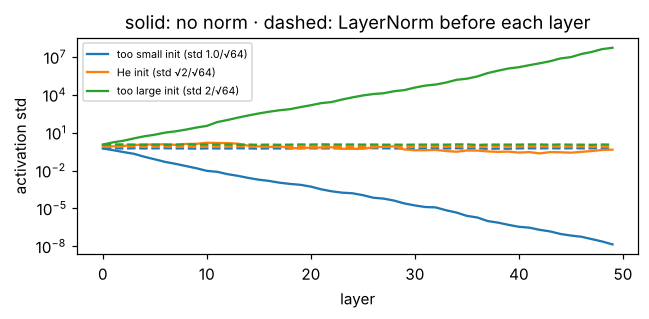

In [5]:
rng = np.random.default_rng(0)
x = rng.standard_normal((256, 64))
scales = {"too small init (std 1.0/√64)": 1.0, "He init (std √2/√64)": np.sqrt(2), "too large init (std 2/√64)": 2.0}
plt.figure(figsize=(6, 3))
for name, g in scales.items():
    h, s, hn, sn = x.copy(), [], x.copy(), []
    for _ in range(50):
        W = rng.standard_normal((64, 64)) * g / 8
        h = np.maximum(h @ W, 0); s.append(h.std())
        hn = np.maximum(layer_norm(hn) @ W, 0); sn.append(hn.std())
    plt.semilogy(s, label=name)
    plt.semilogy(sn, "--", color=plt.gca().lines[-1].get_color())
plt.xlabel("layer"); plt.ylabel("activation std"); plt.title("solid: no norm · dashed: LayerNorm before each layer")
plt.legend(fontsize=7); plt.tight_layout(); plt.show()

Without normalization, the scale changes geometrically with depth unless the initialization is exactly right. With
LayerNorm in front of every layer the scale stays fixed for any initialization. That is why normalization (with
residuals) is part of every modern block: it makes training insensitive to initialization and learning-rate
details.

**Pre-norm vs. post-norm.** The original Transformer normalized *after* the residual add:
$x \leftarrow \text{Norm}(x + F(x))$. Most current models normalize the *input* of the branch:
$x \leftarrow x + F(\text{Norm}(x))$. This leaves the residual stream untouched, so the identity gradient path of §1
is clean, and deep stacks train without careful learning-rate warm-up.

## 3. Attention: content-based mixing between tokens

For each token, attention computes a weighted average of all tokens' value vectors. The weights come from how well
its query matches their keys: $\text{softmax}(QK^\top/\sqrt d)\,V$. Three properties follow:

- **Content-based:** *which* tokens are mixed depends on the data, not on a fixed pattern (unlike convolution).
- **All-to-all in one step:** any token can read any other, at $O(n^2)$ cost in the sequence length.
- **Order-blind:** without position information, shuffling the input just shuffles the output.

In [6]:
rng = np.random.default_rng(1)
n, d = 6, 8
Xtok = rng.standard_normal((n, d))
Wq, Wk, Wv = (rng.standard_normal((d, d)) / np.sqrt(d) for _ in range(3))


def attend(X):
    S = (X @ Wq) @ (X @ Wk).T / np.sqrt(d)
    A = np.exp(S - S.max(1, keepdims=True)); A /= A.sum(1, keepdims=True)
    return A @ (X @ Wv)


shuffle = rng.permutation(n)
print("shuffle the tokens, then attend == attend, then shuffle:", np.allclose(attend(Xtok[shuffle]), attend(Xtok)[shuffle]))


def sinusoidal_positions(n, d):
    pos, i = np.arange(n)[:, None], np.arange(d // 2)[None]
    ang = pos / 10000 ** (2 * i / d)
    return np.concatenate([np.sin(ang), np.cos(ang)], 1)


P = sinusoidal_positions(n, d)
print("with position encodings added, the same test:", np.allclose(attend(Xtok[shuffle] + P), attend(Xtok + P)[shuffle]))

shuffle the tokens, then attend == attend, then shuffle: True
with position encodings added, the same test: False


**RoPE** (rotary position embedding, used by most current LLMs) rotates each pair of query/key dimensions by an angle
proportional to the position. The dot product of a query at position $m$ and a key at position $n$ then depends only
on the **relative** offset $m - n$:

In [7]:
def rope(v, pos, base=10000.0):
    half = len(v) // 2
    theta = pos / base ** (np.arange(half) / half)
    c, s = np.cos(theta), np.sin(theta)
    return np.concatenate([v[:half] * c - v[half:] * s, v[:half] * s + v[half:] * c])


q, k = rng.standard_normal(8), rng.standard_normal(8)
for m, nn in [(5, 2), (105, 102), (1005, 1002), (7, 2)]:
    print(f"query at {m:5d}, key at {nn:5d} (offset {m - nn}): score = {rope(q, m) @ rope(k, nn):.4f}")

query at     5, key at     2 (offset 3): score = -0.1319
query at   105, key at   102 (offset 3): score = -0.1319
query at  1005, key at  1002 (offset 3): score = -0.1319
query at     7, key at     2 (offset 5): score = -1.5806


Same offset, same score, wherever the pair sits in the sequence. A pattern learned at one position transfers to all
others.

## 4. The MLP, and why gated MLPs (GLU / SwiGLU) took over

The MLP works on each token separately: it expands the vector ($d \to 4d$), applies a nonlinearity, and projects
back ($4d \to d$). One useful picture: each hidden unit is a **key** that tests the input for a pattern, and its
column of the output matrix is the **value** written into the residual stream when the pattern is present (Geva et
al. 2021). That is the "asking questions" intuition, made precise.

A **gated linear unit** multiplies two projections: $\text{GLU}(x) = (\text{SiLU}(xW_1) \odot xW_3)\,W_2$. The
product lets the block compute multiplicative interactions ("feature $a$ matters *only if* feature $b$ is present")
directly, which a ReLU MLP must approximate piece by piece. Experiment: learn $f(x) = x_1 x_2$ with the same number of
parameters.

In [8]:
def relu_mlp(p, x):
    return jax.nn.relu(x @ p["W1"]) @ p["W2"]


def glu_mlp(p, x):
    return (jax.nn.silu(x @ p["W1"]) * (x @ p["W3"])) @ p["W2"]


def make(kind, hidden, key):
    k = jax.random.split(key, 3)
    p = {"W1": jax.random.normal(k[0], (3, hidden)) * 0.5, "W2": jax.random.normal(k[1], (hidden, 1)) / np.sqrt(hidden)}
    if kind == "glu":
        p["W3"] = jax.random.normal(k[2], (3, hidden)) * 0.5
    return p


def add_bias(x):
    return jnp.concatenate([x, jnp.ones((len(x), 1))], 1)


xs_test = np.random.default_rng(9).uniform(-2, 2, (2000, 2)).astype(np.float32)
for kind, hidden, f in [("ReLU MLP", 24, relu_mlp), ("GLU MLP ", 16, glu_mlp)]:
    p0 = make("glu" if f is glu_mlp else "relu", hidden, jax.random.PRNGKey(0))
    n_par = sum(v.size for v in p0.values())
    loss = lambda p, x: jnp.mean((f(p, add_bias(x))[:, 0] - x[:, 0] * x[:, 1]) ** 2)
    p, _ = train_adam(loss, p0, 3000, lr=3e-3,
                      batch_fn=lambda r: (r.uniform(-2, 2, (256, 2)).astype(np.float32),))
    print(f"{kind}: {n_par} parameters, test MSE on x1*x2 = {float(loss(p, xs_test)):.4f}  (variance of target ≈ 1.78)")

ReLU MLP: 96 parameters, test MSE on x1*x2 = 0.0023  (variance of target ≈ 1.78)


GLU MLP : 112 parameters, test MSE on x1*x2 = 0.0001  (variance of target ≈ 1.78)


With about the same parameter budget the gated MLP's error is roughly 20 times lower. Shazeer (2020) found GLU variants
consistently better in Transformers, and SwiGLU is now the default MLP in LLaMA-style models.

## 5. Convolution: local, shared, translation-equivariant

A convolution applies the same small filter at every position. Two built-in assumptions (inductive biases):
**locality** (nearby pixels matter most) and **weight sharing** (a pattern means the same thing anywhere). The
consequence is **translation equivariance**: shift the input, and the output shifts the same way.

In [9]:
img = np.zeros((12, 12)); img[3:6, 2] = 1; img[3, 2:5] = 1        # a small corner shape
kernel = np.array([[1, 1, 1], [1, -8, 1], [1, 1, 1]], float)       # an edge detector


def conv2d(x, k):
    p = np.pad(x, 1)
    return np.array([[np.sum(p[i:i + 3, j:j + 3] * k) for j in range(x.shape[1])] for i in range(x.shape[0])])


shifted = np.roll(img, (4, 5), (0, 1))
print("conv(shift(x)) == shift(conv(x)):", np.allclose(conv2d(shifted, kernel), np.roll(conv2d(img, kernel), (4, 5), (0, 1))))
print("parameters to map a 224×224×64 feature map to 224×224×64:")
print(f"  3×3 convolution: {3 * 3 * 64 * 64:,}")
print(f"  dense layer:     {(224 * 224 * 64) ** 2:,}")
for layers in [1, 2, 4, 8]:
    print(f"receptive field after {layers} 3×3 layers: {2 * layers + 1}×{2 * layers + 1} "
          f"(with dilation doubling each layer: {2 ** (layers + 1) - 1}×{2 ** (layers + 1) - 1})")

conv(shift(x)) == shift(conv(x)): True
parameters to map a 224×224×64 feature map to 224×224×64:
  3×3 convolution: 36,864
  dense layer:     10,312,216,477,696
receptive field after 1 3×3 layers: 3×3 (with dilation doubling each layer: 3×3)
receptive field after 2 3×3 layers: 5×5 (with dilation doubling each layer: 7×7)
receptive field after 4 3×3 layers: 9×9 (with dilation doubling each layer: 31×31)
receptive field after 8 3×3 layers: 17×17 (with dilation doubling each layer: 511×511)


Convolutions see far only through depth, pooling or dilation. That is why CNNs downsample and why U-Nets have an
encoder–decoder shape: the coarse levels see the whole image, and skip connections bring back the fine detail.
(See the U-Net in [the diffusion notebook](../18-diffusion-and-image-generation/diffusion_digits.ipynb).)

## 6. Gated recurrence and state-space models: what to remember

A linear recurrence $h_t = a\,h_{t-1} + (1-a)\,x_t$ is the simplest memory. With a **fixed** decay $a$, the memory
fades as $a^k$: information from $k$ steps ago is down by a factor $a^k$. LSTMs, GRUs and **selective** state-space
models (Mamba) make the decay **input-dependent**, so the model can decide *per token* to write, keep or overwrite.

Task: a stream of random values; one token is "marked", and at the end we want its value back. No training here: we
compare the best fixed decay with a hand-set selective gate, to see what the mechanism makes possible.

In [10]:
rng = np.random.default_rng(0)
L, trials = 200, 2000
vals = rng.standard_normal((trials, L))
mark = rng.integers(0, L // 2, trials)                   # the marked token is somewhere in the first half
target = vals[np.arange(trials), mark]


def run(gate):                                           # gate: (trials, L) values of a_t
    h = np.zeros(trials)
    for t in range(L):
        h = gate[:, t] * h + (1 - gate[:, t]) * vals[:, t]
    return h


print("fixed decay a (same for every token):")
for a in [0.5, 0.9, 0.99, 0.999]:
    h = run(np.full((trials, L), a))
    print(f"  a = {a:<6}: correlation with the marked value {np.corrcoef(h, target)[0, 1]:.3f}")
sel = np.ones((trials, L)); sel[np.arange(trials), mark] = 0.0      # selective: overwrite at the mark, keep otherwise
print(f"selective gate (a_t = 0 at the marked token, 1 elsewhere): correlation {np.corrcoef(run(sel), target)[0, 1]:.3f}")

fixed decay a (same for every token):
  a = 0.5   : correlation with the marked value -0.016
  a = 0.9   : correlation with the marked value 0.038
  a = 0.99  : correlation with the marked value 0.071
  a = 0.999 : correlation with the marked value 0.103
selective gate (a_t = 0 at the marked token, 1 elsewhere): correlation 1.000


A fixed decay either forgets the marked value (small $a$) or drowns it in everything else (large $a$). An
input-dependent gate solves the task exactly. That is the LSTM's forget gate (1997) and the "selective" in Mamba's
selective state-space model (2023). Mamba computes this recurrence with a parallel scan, so it trains like a
Transformer but costs $O(n)$ in sequence length rather than $O(n^2)$.

## 7. Mixture of experts: more parameters, same compute per token

A mixture-of-experts layer replaces the one MLP by $E$ expert MLPs plus a small **router** that sends each token to
its top-$k$ experts (here $k = 1$). Total parameters grow $E$-fold, but each token still runs one expert.

Task: a regression target that follows a different rule in each of four regions of the input space. We compare one
MLP with hidden width 16 against four experts of width 16 each (same compute per input).

In [11]:
def target_fn(x):
    q = (x[:, 0] > 0).astype(int) * 2 + (x[:, 1] > 0).astype(int)
    rules = jnp.stack([jnp.sin(3 * x[:, 0]), x[:, 0] * x[:, 1] * 2, jnp.cos(4 * x[:, 1]), jnp.abs(x[:, 0] - x[:, 1])], 1)
    return rules[jnp.arange(len(x)), q]


def mlp_params(key, hidden=16):
    k = jax.random.split(key, 2)
    return dict(W1=jax.random.normal(k[0], (2, hidden)), b1=jnp.zeros(hidden),
                W2=jax.random.normal(k[1], (hidden, 1)) / np.sqrt(hidden), b2=jnp.zeros(1))


def mlp(p, x):
    return (jnp.tanh(x @ p["W1"] + p["b1"]) @ p["W2"] + p["b2"])[:, 0]


def moe_params(key, E=4):
    ks = jax.random.split(key, E + 1)
    return dict(router=jax.random.normal(ks[0], (2, E)) * 0.1, experts=[mlp_params(k) for k in ks[1:]])


def moe(p, x, return_route=False):
    gates = jax.nn.softmax(x @ p["router"] * 5, -1)                       # router probabilities
    top = jnp.argmax(gates, -1)                                           # top-1 routing
    outs = jnp.stack([mlp(e, x) for e in p["experts"]], 1)               # (computed densely here for simplicity)
    y = outs[jnp.arange(len(x)), top] * gates[jnp.arange(len(x)), top]   # scaled by the gate so the router gets gradient
    return (y, top) if return_route else y


xs = np.random.default_rng(3).uniform(-1.5, 1.5, (4000, 2)).astype(np.float32)
bf = lambda r: (r.uniform(-1.5, 1.5, (256, 2)).astype(np.float32),)
for name, f, p0 in [("dense MLP (1 × 16 units)", mlp, mlp_params(jax.random.PRNGKey(0))),
                    ("MoE (4 experts × 16 units, top-1)", moe, moe_params(jax.random.PRNGKey(0)))]:
    loss = lambda p, x: jnp.mean((f(p, x) - target_fn(x)) ** 2)
    p, _ = train_adam(loss, p0, 4000, lr=3e-3, batch_fn=bf)
    n_par = sum(v.size for v in jax.tree_util.tree_leaves(p0))
    print(f"{name:36s} params {n_par:4d}   test MSE {float(loss(p, xs)):.4f}")
_, route = moe(p, xs, return_route=True)
q = (xs[:, 0] > 0).astype(int) * 2 + (xs[:, 1] > 0).astype(int)
print("which expert handles each region (rows: region, columns: expert):")
print(np.array([[np.mean(np.asarray(route)[q == r] == e) for e in range(4)] for r in range(4)]).round(2))

dense MLP (1 × 16 units)             params   65   test MSE 0.0255


MoE (4 experts × 16 units, top-1)    params  268   test MSE 0.0086
which expert handles each region (rows: region, columns: expert):
[[0.02 0.   0.   0.98]
 [0.   0.   0.85 0.15]
 [1.   0.   0.   0.  ]
 [0.56 0.36 0.08 0.  ]]


The router learns to split the input space and the experts specialise (mostly one expert per region; the last region
is shared by two), so the MoE fits the piecewise target about three times better at the same per-token compute. Large MoE LLMs (Switch Transformer, Mixtral, DeepSeek-V3) use the same idea
with hundreds of experts and extra losses that keep the load balanced.

## Summary: what each block is for

| Block | Mixes | Main benefit | Price |
| --- | --- | --- | --- |
| Residual connection | – | trainable depth, blocks learn corrections | none |
| LayerNorm / RMSNorm | – (per token) | stable scale, insensitive to init and step size | small |
| Attention | between tokens, by content | any token reads any other in one layer | $O(n^2)$ in length; needs positions |
| MLP / GLU | within a token | most of the parameters and "knowledge" | – |
| Convolution | between neighbours | locality, sharing, few parameters | sees far only through depth |
| Gated recurrence / SSM | between tokens, in order | $O(n)$ memory over long sequences | must compress the past into a state |
| Mixture of experts | within a token | capacity without compute | routing, load balancing, memory |